# Pre-training on the pop-cosmos mock

Trains a `znn` model from scratch on the pop-cosmos mock and saves it as a pre-training, for the architecture
`ARCH` and target `TARGET` set below. It is saved as `znn/pretrained/popcosmos_<ARCH>_<TARGET>.{json,npz}`
(`znn.pretrained_name`), the file `pretraining="popcosmos"` loads when training that architecture with that
target.

- **Data:** the mock in its 23 COSMOS2020 bands inside the LSST ugrizy + Roman Y106/J129/H158 range, encoded on
  the default grid shared with the challenge catalogues. `popcosmos_encoding.ipynb` has the band selection and
  a study of the encoding.
- **Same galaxies for every pre-training:** the training and test sets are drawn exactly as in
  `CNN_photoz-ensemble-popcosmos.ipynb`, which trained the shipped `popcosmos_build_model_z3`. All
  architectures are pre-trained on the same 200k galaxies, and the test set is disjoint from all of them.
- **Training:** one model, from scratch with `znn.train_model`, on the photometry as given. A random
  `VAL_FRAC` = 20% of the training set is held out for early stopping, so it trains on 160k galaxies,
  as many as the shipped model (member 0 of a 5-fold ensemble). The model is saved to `MODEL_FILE` and
  reloaded on re-runs instead of being retrained.
- **Check:** before saving, the test-set scores are compared with the shipped `popcosmos_build_model_z3`.

Run this from the repo root.

## Configuration

In [1]:
import datetime
import hashlib
import os
import subprocess

import h5py
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

import znn  # run from the repo root so this picks up the local source

# What to pre-train: the architecture and target the pre-training is for. Training with pretraining=NAME picks
# the weights saved here when it uses the same architecture and target (see znn.pretrained_name)
ARCH = znn.build_model_res_se
TARGET = "log1pz"
LOSS = "mse"

NAME = "popcosmos"
STEM = znn.pretrained_name(NAME, ARCH, TARGET)  # e.g. popcosmos_build_model_res_se_log1pz
PRETRAINED_PATH = os.path.join(znn.PRETRAINED_DIR, STEM)  # the pre-training, as <path>.json + <path>.npz
MODEL_FILE = f"models/popcosmos/{STEM}.pkl"  # the trained model, reloaded on re-runs
OVERWRITE = False  # True to replace a pre-training already saved at PRETRAINED_PATH
# The layer up to which training from this pre-training keeps the model frozen (that layer and every layer it depends
# on; see znn.save_pretrained). For build_model_res_se, "activation_2" ends the first residual block: the stem, both
# convs, the SE gate and the skip. None freezes the first znn.models.N_FROZEN_LAYERS layers (as for build_model)
FROZEN_UNTIL = "activation_2" if ARCH is znn.build_model_res_se else None

MOCK_FILE = "mock_catalog_Ch1_26.h5"
FILTER_DIR = "data/popcosmos_filters"
I_MAX = 25.5  # magnitude cut in HSC i
N_TRAIN = 200_000  # training objects, of which VAL_FRAC are held out for early stopping
N_TEST = 50_000  # held-out test objects, disjoint from the training sample
SEED = 42  # the selection, as in CNN_photoz-ensemble-popcosmos.ipynb, and the validation split

VAL_FRAC = 0.2  # held out for early stopping and learning-rate reduction
EPOCHS = 100  # max epochs (early stopping usually ends sooner)

# (band, filter file) in the mock's column order; see data/popcosmos_filters/SOURCES.md
MOCK_BANDS = [
    ("u", "u_megaprime_sagem.res"),
    ("g", "hsc_g.res"),
    ("r", "hsc_r.res"),
    ("i", "hsc_i.res"),
    ("z", "hsc_z.res"),
    ("y", "hsc_y.par"),
    ("Y", "uvista_y_cosmos.par"),
    ("J", "uvista_j_cosmos.par"),
    ("H", "uvista_h_cosmos.par"),
    ("Ks", "uvista_ks_cosmos.par"),
    *[
        (name, f"ia{name[2:]}_cosmos.par")
        for name in ["IB427", "IB464", "IA484", "IB505", "IA527", "IB574",
                     "IA624", "IA679", "IB709", "IA738", "IA767", "IB827"]
    ],
    ("NB711", "NB711.SuprimeCam.par"),
    ("NB816", "NB816.SuprimeCam.par"),
    ("ch1", "irac1_cosmos.par"),
    ("ch2", "irac2_cosmos.par"),
]
MOCK_COLUMN = {band: k for k, (band, _) in enumerate(MOCK_BANDS)}
REF_BAND = "i"

# Wavelength span of the DC2LSST_{ugrizy} and roman_{Y106,J129,H158} curves used for the challenge. The
# pre-training must be on the grid of the data it is used on: the default one
LAMBDA_RANGE = (3000.0, 18650.0)  # Å
CONFIG = {**znn.DEFAULT_FEATURE_CONFIG, "lambda_range": LAMBDA_RANGE}
assert CONFIG == znn.DEFAULT_FEATURE_CONFIG, "the default grid has changed; pre-trainings must be on it"

I0000 00:00:1793635700.922649  132152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793635700.923008  132152 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793635700.954629  132152 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793635702.099404  132152 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

## Bands within the LSST/Roman range

A band is kept if its response above 1% of its peak lies inside `LAMBDA_RANGE`, as in
`popcosmos_encoding.ipynb`. This drops Ks and IRAC ch1/ch2 and keeps 23 bands.

In [2]:
def response_range(curve, level=0.01):
    w, t = curve.T
    w = w[t > level * t.max()]
    return w.min(), w.max()


all_curves = {band: np.loadtxt(f"{FILTER_DIR}/{file}") for band, file in MOCK_BANDS}
kept = [b for b, c in all_curves.items() if LAMBDA_RANGE[0] <= response_range(c)[0] and response_range(c)[1] <= LAMBDA_RANGE[1]]
print(f"keeping {len(kept)} bands; dropping {[b for b in all_curves if b not in kept]}")

BANDS = {b: (f"mag_{b}", f"{FILTER_DIR}/{file}") for b, file in MOCK_BANDS if b in kept}
filter_curves = znn.load_filter_curves(BANDS)

keeping 23 bands; dropping ['Ks', 'ch1', 'ch2']


## Load the mock and draw the training and test sets

Fluxes are in maggies; negative noisy fluxes become non-detections (`NaN`, treated as unobserved). Redshift is
column 15 of `sps_parameters`. The photometry is the mock's own noisy fluxes, at COSMOS2020 depth (much deeper
than LSST in the optical).

The sets are drawn as in `CNN_photoz-ensemble-popcosmos.ipynb`: one random permutation (seed `SEED`) of the
galaxies with i < `I_MAX`, of which the first `N_TRAIN` are the training set and the next `N_TEST` the test set.

In [3]:
with h5py.File(MOCK_FILE, "r") as f:
    fluxes = f["fluxes"][:]
    sigmas = f["flux_sigmas"][:]
    redshift = f["sps_parameters"][:, 15]

with np.errstate(divide="ignore", invalid="ignore"):
    detected = fluxes > 0
    mags = np.where(detected, -2.5 * np.log10(fluxes), np.nan)
    mag_errs = np.where(detected, 2.5 / np.log(10) * sigmas / fluxes, np.nan)

passing = np.flatnonzero(mags[:, MOCK_COLUMN[REF_BAND]] < I_MAX)
chosen = np.random.default_rng(SEED).permutation(passing)
idx = {"train": np.sort(chosen[:N_TRAIN]), "test": np.sort(chosen[N_TRAIN:N_TRAIN + N_TEST])}


def mock_catalog(rows):
    return pd.DataFrame(
        {
            **{column: mags[rows, MOCK_COLUMN[b]] for b, (column, _) in BANDS.items()},
            **{f"{column}_err": mag_errs[rows, MOCK_COLUMN[b]] for b, (column, _) in BANDS.items()},
            "redshift": redshift[rows],
        }
    )


train = mock_catalog(idx["train"])
test = mock_catalog(idx["test"])
print(f"{len(passing):,} mock galaxies with i < {I_MAX}; train {len(train):,}, test {len(test):,}")
del fluxes, sigmas, mags, mag_errs

1,048,241 mock galaxies with i < 25.5; train 200,000, test 50,000


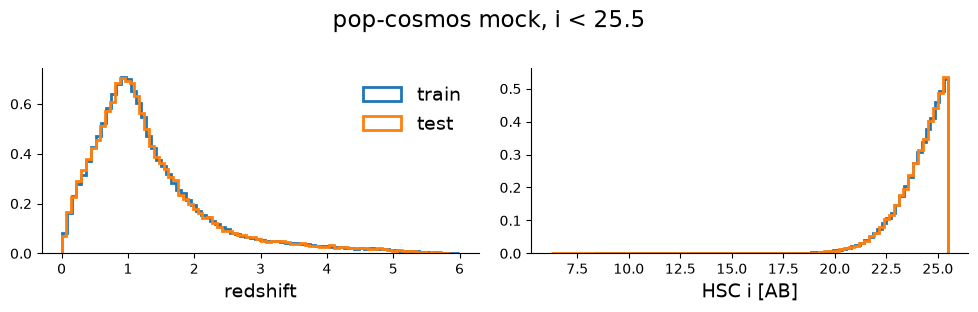

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for name, df in [("train", train), ("test", test)]:
    axes[0].hist(df["redshift"], bins=80, histtype="step", lw=2, density=True, label=name)
    axes[1].hist(df[f"mag_{REF_BAND}"], bins=80, histtype="step", lw=2, density=True, label=name)
axes[0].set_xlabel("redshift")
axes[1].set_xlabel("HSC i [AB]")
axes[0].legend(frameon=False)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"pop-cosmos mock, i < {I_MAX}")
fig.tight_layout()
plt.show()

## Encode

In [5]:
X_train, Y_train = znn.catalog_to_XY(train, BANDS, REF_BAND, CONFIG, filter_curves=filter_curves)
X_test, Y_test = znn.catalog_to_XY(test, BANDS, REF_BAND, CONFIG, filter_curves=filter_curves)
print("train:", X_train.shape, "test:", X_test.shape, " all finite:", np.isfinite(X_train).all() and np.isfinite(X_test).all())

train: (200000, 32, 3) test: (50000, 32, 3)  all finite: True


## Train the model (or load it if already trained)

From scratch (`pretraining=None`), with `TARGET` and `LOSS`. The model is saved as a one-member ensemble.
Delete `MODEL_FILE` to retrain.

E0000 00:00:1793635704.728607  132152 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Epoch 1/100
625/625 - 47s - 76ms/step - loss: 0.0961 - val_loss: 0.0470 - learning_rate: 0.0010
Epoch 2/100
625/625 - 39s - 62ms/step - loss: 0.0571 - val_loss: 0.0366 - learning_rate: 0.0010
Epoch 3/100
625/625 - 27s - 43ms/step - loss: 0.0490 - val_loss: 0.0855 - learning_rate: 0.0010
Epoch 4/100
625/625 - 26s - 41ms/step - loss: 0.0449 - val_loss: 0.0399 - learning_rate: 0.0010
Epoch 5/100
625/625 - 24s - 39ms/step - loss: 0.0412 - val_loss: 0.0322 - learning_rate: 0.0010
Epoch 6/100
625/625 - 24s - 38ms/step - loss: 0.0411 - val_loss: 0.0306 - learning_rate: 0.0010
Epoch 7/100
625/625 - 23s - 37ms/step - loss: 0.0392 - val_loss: 0.0417 - learning_rate: 0.0010
Epoch 8/100
625/625 - 23s - 36ms/step - loss: 0.0374 - val_loss: 0.0398 - learning_rate: 0.0010
Epoch 9/100

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
625/625 - 28s - 44ms/step - loss: 0.0378 - val_loss: 0.0338 - learning_rate: 0.0010
Epoch 10/100
625/625 - 27s - 43ms/step - loss: 0.0309 - val

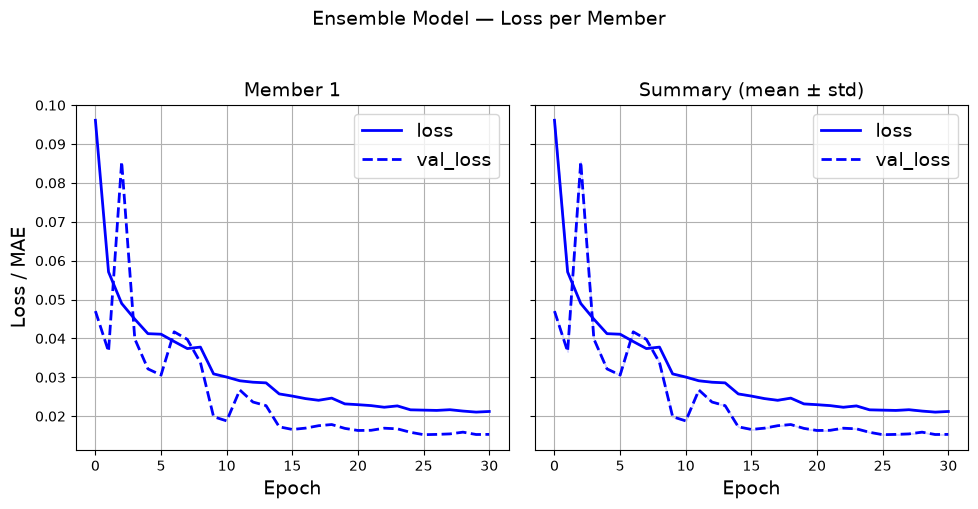

In [6]:
if os.path.exists(MODEL_FILE):
    trained_models, features = znn.load_ensemble_file(MODEL_FILE)
    assert features["config"] == CONFIG and list(features["bands"]) == list(BANDS), "MODEL_FILE was trained with other settings"
    history = None
    print("loaded", MODEL_FILE)
else:
    member, history = znn.train_model(
        ARCH, X_train, Y_train, VAL_FRAC=VAL_FRAC, EPOCHS=EPOCHS, random_state=SEED, pretraining=None,
        target=TARGET, loss=LOSS,
    )
    trained_models = [member]
    os.makedirs(os.path.dirname(MODEL_FILE), exist_ok=True)
    znn.save_ensemble_file(MODEL_FILE, trained_models, BANDS, REF_BAND, CONFIG)
    print("saved", MODEL_FILE)

if history is not None:
    znn.plot_ensemble_losses([history], ylim=None)  # the loss is in the units of TARGET
    plt.show()

## Test-set check

On the test set, which neither model saw, compare the model trained here with the shipped
`popcosmos_build_model_z3`, trained on the same galaxies.

Δz = (z_phot − z_true)/(1 + z_true). Bias and
scatter are biweight estimates after 3σ clipping (`znn.get_biweight_mean_sigma_outlier`).

In [7]:
def point_predictions(members, X):
    # mean of the members' redshift predictions
    return np.mean([model.predict(X, batch_size=4096, verbose=0).ravel() * Y_std + Y_mean for model, Y_mean, Y_std in members], axis=0)


def point_stats(z_pred):
    bias, _, scatter, outlier_rate, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier((z_pred - Y_test) / (1 + Y_test))
    return {"bias": bias, "scatter": scatter, "outlier rate (3σ)": outlier_rate, "outlier rate (|Δz| > 0.2)": abs_outlier_rate}


reference, _, _ = znn.load_pretrained(NAME, znn.build_model, "z3")
NEW = f"{ARCH.__name__}, {TARGET} (this notebook)"
candidates = {NEW: trained_models, "shipped build_model, z3": reference}
z_pred = {name: point_predictions(members, X_test) for name, members in candidates.items()}
test_stats = {name: point_stats(z) for name, z in z_pred.items()}
pd.DataFrame(test_stats).T.round(4)

I0000 00:00:1793636422.658695  132275 service.cc:153] XLA service 0x79853002fba0 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793636422.658709  132275 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1793636422.665164  132275 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793636422.815418  132275 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


,bias,scatter,outlier rate (3σ),outlier rate (|Δz| > 0.2)
"build_model_res_se, log1pz (this notebook)",-0.0001,0.0171,0.0476,0.0048
"shipped build_model, z3",0.0013,0.0193,0.0554,0.0076


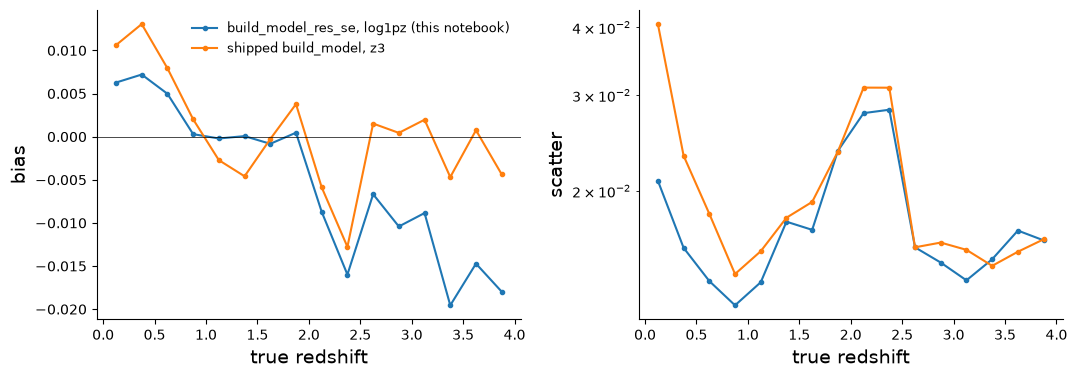

In [8]:
# scatter and bias in bins of true redshift
redshift_bins = np.linspace(0, 4, 17)
centres = 0.5 * (redshift_bins[1:] + redshift_bins[:-1])
which = np.digitize(Y_test, redshift_bins) - 1

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, z in z_pred.items():
    dz = (z - Y_test) / (1 + Y_test)
    # (bias, its error, scatter, outlier rates) per bin; bins with too few objects are left empty
    binned = np.array([
        znn.get_biweight_mean_sigma_outlier(dz[which == k]) if np.sum(which == k) > 50 else (np.nan,) * 5
        for k in range(len(centres))
    ])
    axes[0].plot(centres, binned[:, 0], "-o", ms=3, label=name)
    axes[1].plot(centres, binned[:, 2], "-o", ms=3, label=name)
axes[0].axhline(0, color="k", lw=0.5)
axes[0].set_ylabel("bias")
axes[1].set_ylabel("scatter")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("true redshift")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## Save the pre-training

Saves the model to `PRETRAINED_PATH` with its provenance (`znn.save_pretrained`). An existing pre-training
there is replaced only with `OVERWRITE = True`. The check afterwards loads it back by name, as `pretraining=NAME`
does for `ARCH` and `TARGET`, and compares its predictions with those of the model it was saved from.

To ship it with `znn`, commit the two files. They are installed with the package (`pyproject.toml`).

In [9]:
if os.path.exists(f"{PRETRAINED_PATH}.json") and not OVERWRITE:
    raise FileExistsError(f"{PRETRAINED_PATH}.json exists; set OVERWRITE = True to replace it")

md5 = hashlib.md5()
with open(MOCK_FILE, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 24), b""):
        md5.update(chunk)


def git(*args):
    return subprocess.run(["git", *args], capture_output=True, text=True).stdout.strip()


info = {
    "description": (
        f"znn {ARCH.__name__} trained on the pop-cosmos mock with target={TARGET!r}: the starting point of "
        f"pretraining={NAME!r} for this architecture and target (one model, trained in the notebook below)"
    ),
    "training_data": {
        "catalogue": f"pop-cosmos {MOCK_FILE}, v1.1.0 (Zenodo 10.5281/zenodo.17132433)",
        "catalogue_md5": md5.hexdigest(),
        "photometry": "the mock's noisy fluxes (COSMOS2020 depth, native noise; not degraded to LSST)",
        "selection": f"HSC i < {I_MAX}",
        "n_train": (
            f"{N_TRAIN} random objects (seed {SEED}), drawn as in CNN_photoz-ensemble-popcosmos.ipynb, of which a "
            f"random {VAL_FRAC:.0%} (seed {SEED}) is held out for early stopping"
        ),
        "bands": list(BANDS),
        "ref_band": REF_BAND,
        "filters": "COSMOS2020 curves used by pop-cosmos (steppz filters + CFHT u_megaprime_sagem)",
    },
    "training": {
        "function": f"znn.train_model(znn.{ARCH.__name__}, ..., pretraining=None, target={TARGET!r}, loss={LOSS!r})",
        "VAL_FRAC": VAL_FRAC,
        "EPOCHS": EPOCHS,
        "random_state": SEED,
        "model_file": MODEL_FILE,
    },
    "test": {"n_test": f"{N_TEST} objects disjoint from the training set (seed {SEED})", **test_stats[NEW]},
    "notebook": "popcosmos_pretraining.ipynb",
    "znn_commit": git("rev-parse", "--short", "HEAD") + (" (with local changes)" if git("status", "--porcelain", "znn") else ""),
    "saved_on": datetime.date.today().isoformat(),
    "versions": {"tensorflow": tf.__version__, "keras": keras.__version__},
}
znn.save_pretrained(PRETRAINED_PATH, trained_models, CONFIG, info, build_model_func=ARCH, frozen_until=FROZEN_UNTIL)
print("saved", f"{PRETRAINED_PATH}.json", f"{PRETRAINED_PATH}.npz")

# Load it back as pretraining=NAME would, and check it predicts as the model it was saved from
loaded, loaded_config, _ = znn.load_pretrained(NAME, ARCH, TARGET)
assert loaded_config == CONFIG
np.testing.assert_allclose(point_predictions(loaded, X_test), z_pred[NEW], atol=1e-5)
print(f"loads as pretraining={NAME!r} for {ARCH.__name__} with target={TARGET!r}, and predicts as saved")

saved /home/jaimerz/Documents/UCL/mlpz_cnn_deepset/znn/pretrained/popcosmos_build_model_res_se_log1pz.json /home/jaimerz/Documents/UCL/mlpz_cnn_deepset/znn/pretrained/popcosmos_build_model_res_se_log1pz.npz
loads as pretraining='popcosmos' for build_model_res_se with target='log1pz', and predicts as saved


## Notes

- **Using it:** `znn.train_from_catalog(ARCH, ..., target=TARGET)` (or `train_ensembles`) with the default
  `pretraining="popcosmos"` now starts from this model. The architecture or target alone is not enough: both
  must match.
- **Frozen layers:** fine-tuning from this pre-training freezes `FROZEN_UNTIL` and every layer it depends on. For
  `build_model_res_se` that is the whole first residual block (`activation_2`: the stem, both convs, the SE gate and the
  skip, 7.8k parameters). Without it, fine-tuning freezes the first `znn.models.N_FROZEN_LAYERS` (4) layers, which in
  `build_model` are its first two conv + pooling blocks.
- **Depth:** the mock's photometry is at COSMOS2020 depth, much deeper than LSST in the optical, and its noise is
  heavier-tailed than its quoted errors (see `popcosmos_encoding.ipynb`). This is the same data as the shipped
  `popcosmos_build_model_z3`, so pre-trainings of different architectures stay comparable.